# 2. Where is burden concentrated? (RQ1)

Global Moran's I tests whether burden is spatially random; local Moran's I (LISA) finds the
clusters, with a false discovery rate correction so hundreds of tests do not overstate significance.
Script: `scripts/03_explore.py`. The statistics below are recomputed live (999 permutations; the
pipeline uses 9,999).

_Part of the Chicago Energy Burden project (James Rocco Quantitative Data Research Scholarship, Lake Forest College). Run the pipeline scripts first, or read the executed copy on GitHub._

In [1]:
import json, warnings
import numpy as np, pandas as pd, geopandas as gpd
from IPython.display import Image, Markdown, display
from ceb import config
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
T, F = config.TABLES, config.FIGURES
gdf = gpd.read_file(config.PROCESSED / "chicago_tracts.gpkg")
sample = gdf[gdf["in_main_sample"].astype(bool)].reset_index(drop=True)
print(f"{len(gdf)} tracts mostly inside Chicago; {len(sample)} in the analysis sample")

782 tracts mostly inside Chicago; 768 in the analysis sample


In [2]:
from esda import Moran, Moran_Local, fdr
from ceb import geo
w = geo.weights(sample, "queen")
y = sample["burden_pct"].to_numpy()
m = Moran(y, w, permutations=999)
print(f"Global Moran's I = {m.I:.3f} (expected under randomness {m.EI:.4f}), pseudo p = {m.p_sim:.4f}")

  note: 1 tract(s) with no touching neighbor ['17043840000']; linked to nearest tract
Global Moran's I = 0.826 (expected under randomness -0.0013), pseudo p = 0.0010


In [3]:
lm = Moran_Local(y, w, permutations=999, seed=config.SEED)
cut = fdr(lm.p_sim, 0.05)
labels = pd.Series(lm.q).map({1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"})
labels[lm.p_sim > cut] = "Not significant"
labels.value_counts()

Not significant    381
Low-Low            202
High-High          182
Low-High             3
Name: count, dtype: int64

## Maps (from the pipeline)

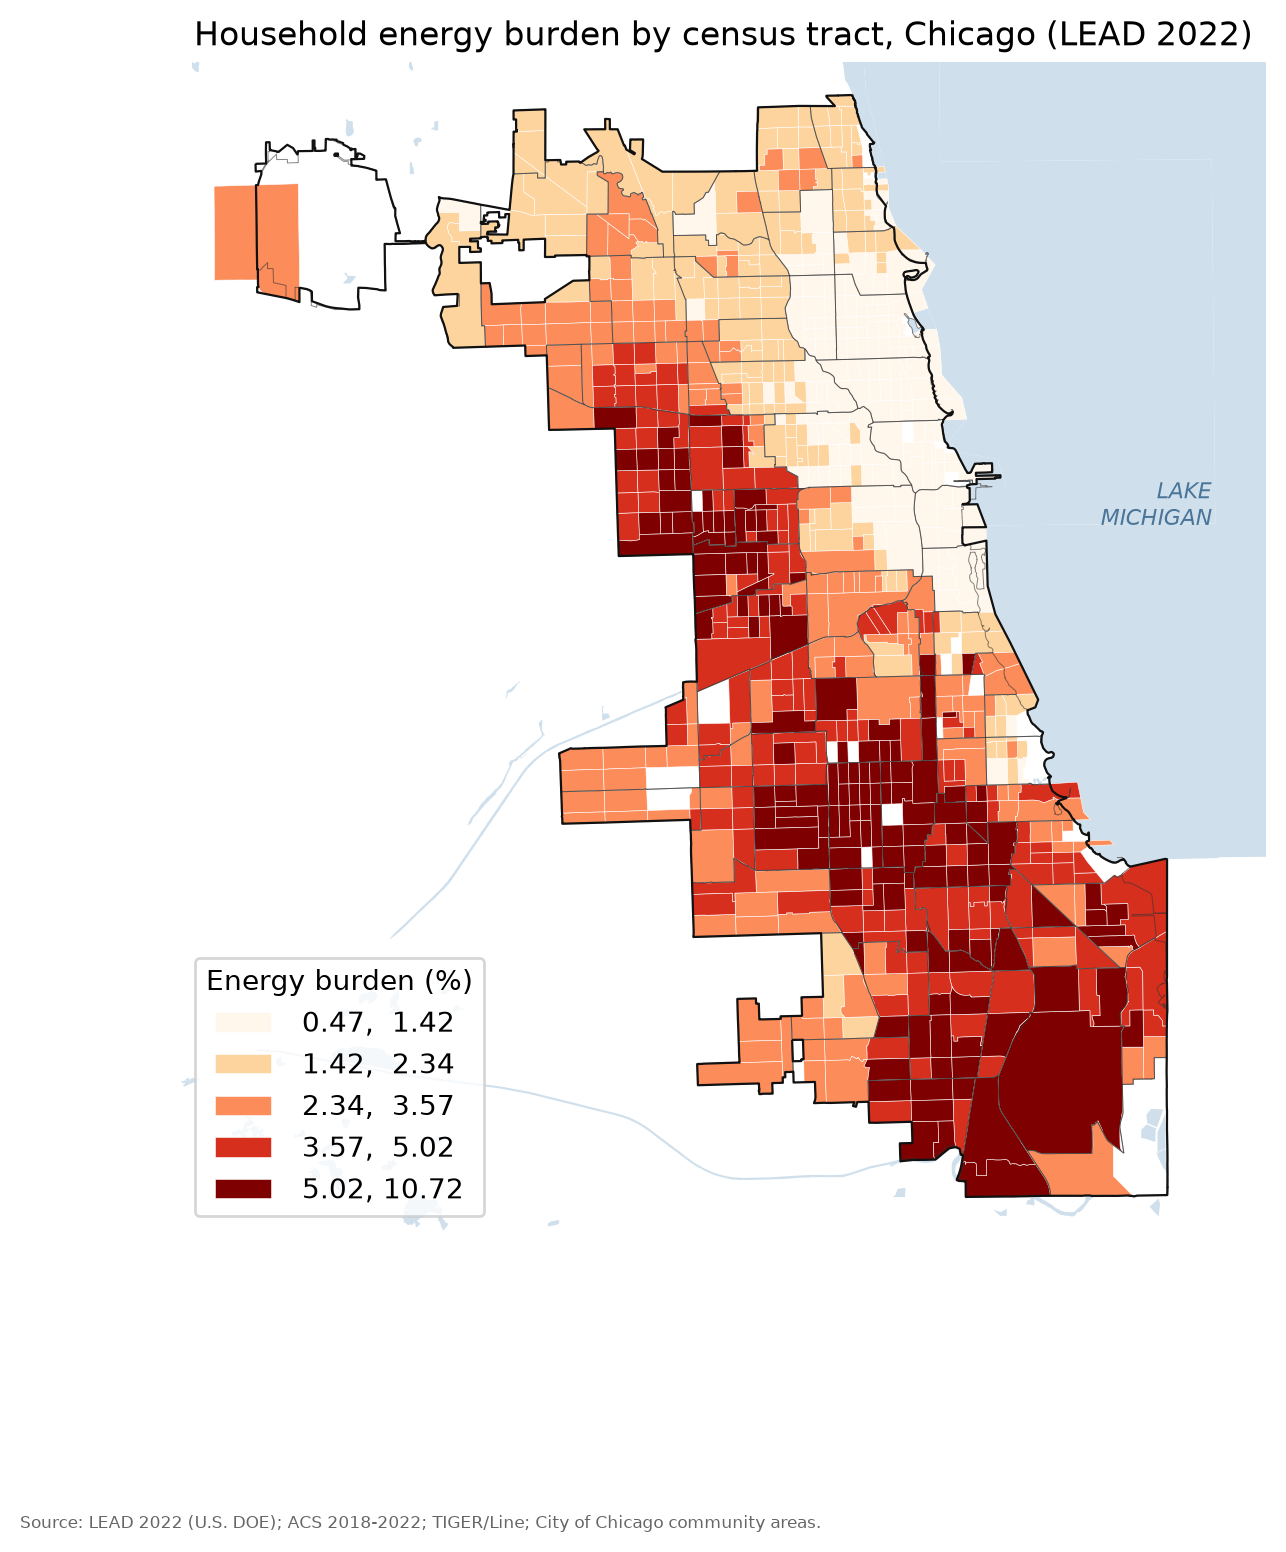

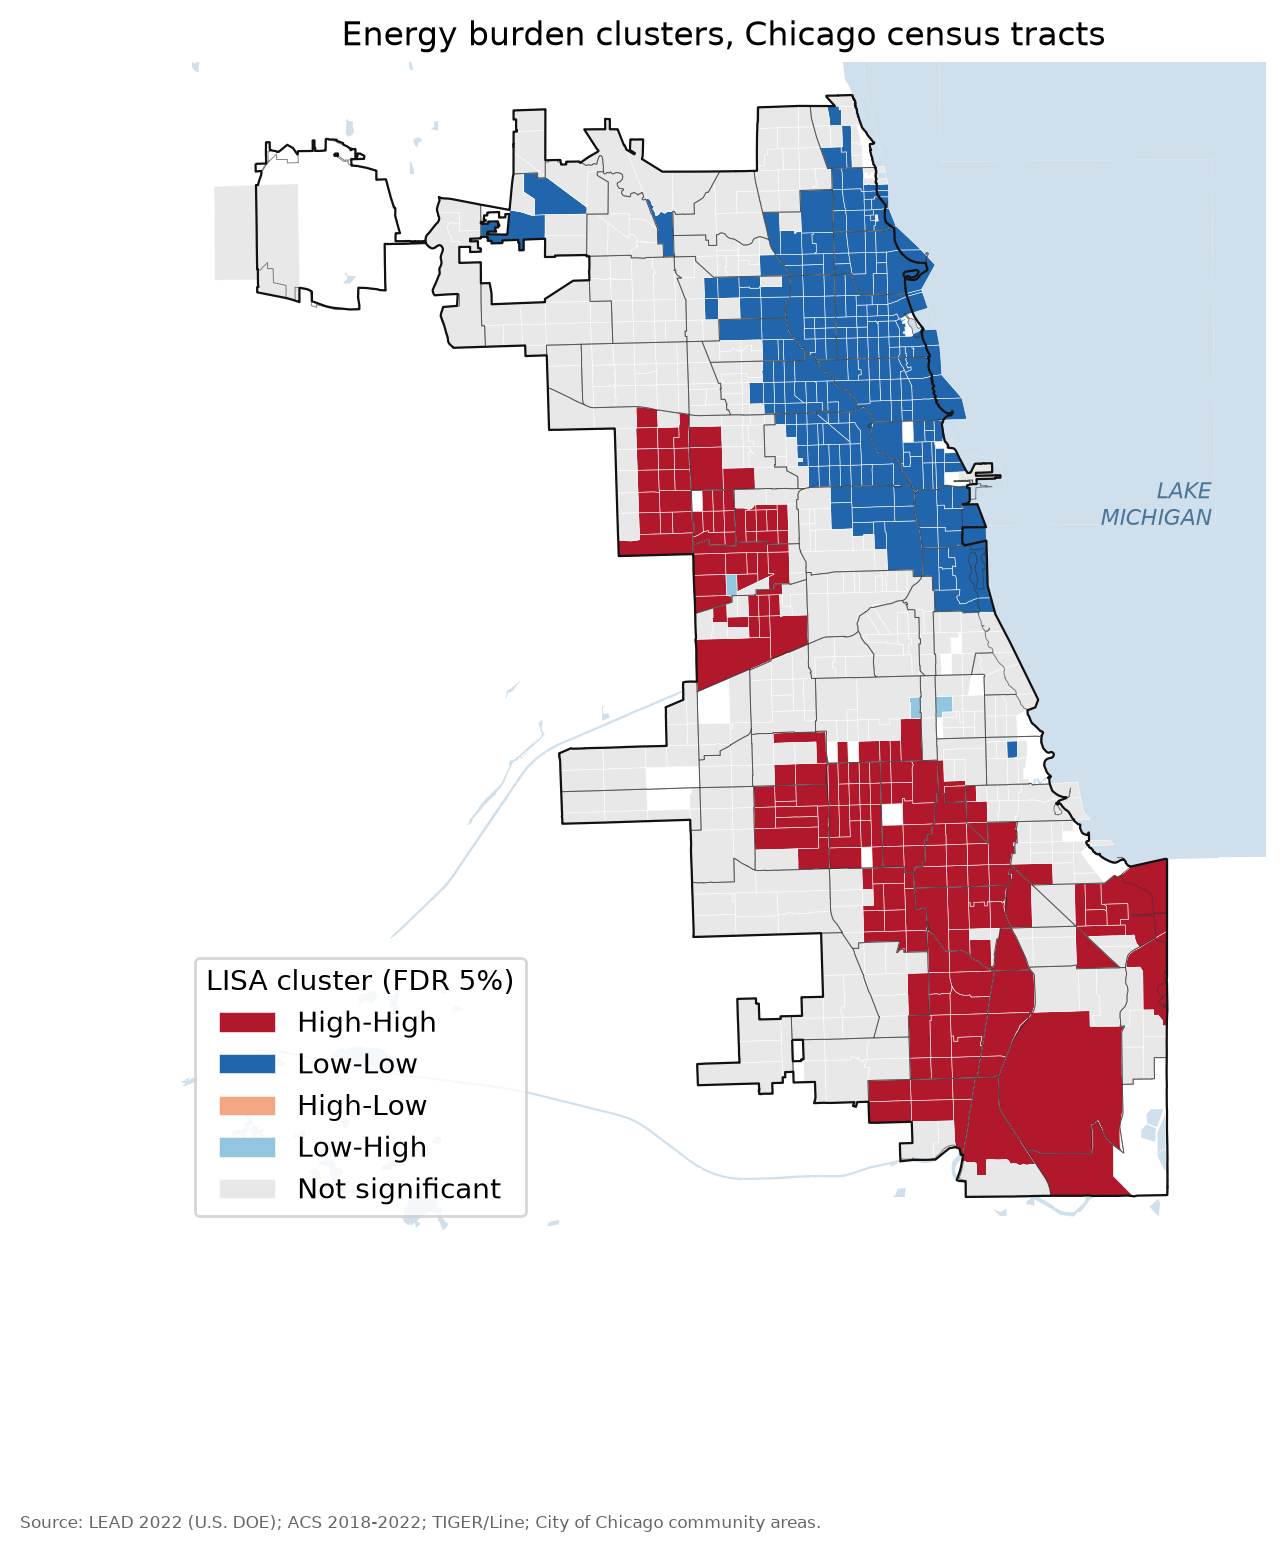

In [4]:
display(Image(F / "map_burden.png", width=520)); display(Image(F / "map_lisa.png", width=520))